# Importing Libraries

In [1]:
# Data manipulation and numerical operations
import pandas as pd   # For data manipulation and analysis
import numpy as np    # For numerical operations

#import shap  # package used to calculate Shap values

# Data visualization libraries
import matplotlib.pyplot as plt   # For plotting and visualizations
import graphviz   # For visualizing decision trees
import seaborn as sns
import plotly.express as px

# Scikit-learn: Model selection and evaluation
from sklearn.model_selection import train_test_split   # For splitting the data into training and testing sets
from sklearn.metrics import accuracy_score, classification_report  # For evaluating model performance
from sklearn.metrics import roc_curve, roc_auc_score, auc  # For calculating ROC curve and AUC
from sklearn.metrics import confusion_matrix

# Scikit-learn: Preprocessing
from sklearn.preprocessing import LabelEncoder   # For encoding categorical labels into numeric values
from sklearn.preprocessing import OneHotEncoder  # For encoding categorical features using one-hot encoding
from sklearn.preprocessing import StandardScaler

# Scikit-learn: Machine learning model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
#from catboost import CatBoostClassifier

# Scikit-learn: Tree visualization
from sklearn.tree import export_graphviz  # For exporting decision trees in DOT format
from sklearn.tree import plot_tree  # For plotting decision trees

from scipy import stats

plt.style.use('fivethirtyeight')
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from imblearn.over_sampling import SMOTE

import joblib

# Parameters

In [2]:
TEST_SIZE = 0.30

USE_ALL_FEATURES = False

USE_SAVE_MODEL = True
USE_TEST_MODEL_PERFORMANCE = True
SHOW_FEATURE_IMPORTANCE = True

USE_SHOW_PLOTS = False
USE_SHOW_MODEL_METRICS = False
SHOW_CLASSIFICATION_REPORT = False
SHOW_ROC_CURVE = False
SHOW_CONFUSION_MATRIX = False


# Loading the Data into a Pandas DataFrame

In [3]:
# Specify the file path to the CSV file containing the thyroid cancer recurrence data
csv_path = "../data/thyroid_diff.csv"

# Read the CSV file into a DataFrame using pandas
df = pd.read_csv(csv_path)

# Display the first few rows of the DataFrame to get a quick overview of the data
# df.head()

if USE_SHOW_PLOTS:
    # Box plot of Age by Gender
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='Recurred', y='Age', data=df)
    plt.title('Box Plot of Age by Recurred')
    plt.xlabel('Recurred')
    plt.ylabel('Age')
    plt.show()

    # Box plot of Age by Stage
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='Stage', y='Age', data=df)
    plt.title('Box Plot of Age by Stage')
    plt.xlabel('Stage')
    plt.ylabel('Age')
    plt.show()

    # Gender by Risk
    plt.figure(figsize=(10, 6))
    sns.countplot(data=df, x='Gender', hue='Risk', palette='viridis')
    plt.title('Grouped Bar Chart of Gender vs Risk')
    plt.show()

    # Scatter plot of Age vs. Tumor size (T)
    fig = px.scatter(df, x='Age', y='T', title='Scatter Plot of Age vs. Tumor size (T)', labels={'T': 'Tumor size (T)', 'Age': 'Age'})

    # Show the plot
    fig.show()

### Label Encoding

In [4]:
# Label encoding yes or no values

# Define mapping
mapping = {'No': 0, 'Yes': 1}

# Insert names of columns that have Yes or No values
boolean_columns = ['Smoking','Hx Smoking','Hx Radiotherapy','Recurred']
df[boolean_columns] = df[boolean_columns].map(mapping.get)

# df.head()

# Label encode features with only 2 values
le = LabelEncoder()

# Input column names that only have 2 values
columns_to_encode = ['Gender','Focality','M']

for column in columns_to_encode:
  df[column] = le.fit_transform(df[column])

# df.head()

# Define mapping for 'Physical Examination'
mapping = {'Normal': 0, 'Diffuse goiter':1, 'Single nodular goiter-left':2, 'Single nodular goiter-right':2,'Multinodular goiter':3}

df['Physical Examination'] = df['Physical Examination'].map(mapping)

if np.isnan(df['Physical Examination'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'Adenopathy'
mapping = {'No': 0, 'Right':1, 'Left':1, 'Posterior':2,'Bilateral':3,'Extensive':4}

df['Adenopathy'] = df['Adenopathy'].map(mapping)

if np.isnan(df['Adenopathy'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'Pathology'
mapping = {'Micropapillary':0,'Papillary':1, 'Follicular':2, 'Hurthle cell':3}

df['Pathology'] = df['Pathology'].map(mapping)

if np.isnan(df['Pathology'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'Risk'
mapping = {'Low':0,'Intermediate':1, 'High':2}

df['Risk'] = df['Risk'].map(mapping)

if np.isnan(df['Risk'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'T'
mapping = {'T1a':0, 'T1b':1, 'T2':2, 'T3a':3, 'T3b':4, 'T4a':5, 'T4b':6}

df['T'] = df['T'].map(mapping)

if np.isnan(df['T'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'N'
mapping = {'N0':0, 'N1a':1, 'N1b':2}

df['N'] = df['N'].map(mapping)

if np.isnan(df['N'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'Stage'
mapping = {'I':0, 'II':1, 'III':2, 'IVA':3, 'IVB':4}

df['Stage'] = df['Stage'].map(mapping)

if np.isnan(df['Stage'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

# Define mapping for 'Response'
mapping = {'Excellent':0, 'Indeterminate':1, 'Biochemical Incomplete':2, 'Structural Incomplete':3}

df['Response'] = df['Response'].map(mapping)

if np.isnan(df['Response'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

### One-Hot Encoding

In [5]:
# Initialize a OneHotEncoder object
ohe = OneHotEncoder()

# Fit the OneHotEncoder to the 'Thyroid Function' column of the dataframe 'df'
# and transform it into a one-hot encoded array. The 'toarray()' method
# converts the sparse matrix output into a dense numpy array.
ohe.fit_transform(df[['Thyroid Function']]).toarray()

# Fit the OneHotEncoder to the 'Thyroid Function' column of the dataframe 'df'
# and transform it into a one-hot encoded array. The 'toarray()' method
# converts the sparse matrix output into a dense numpy array.
feature_array = ohe.fit_transform(df[['Thyroid Function']]).toarray()

# Get the category labels from the fitted OneHotEncoder
feature_labels = ohe.categories_

# Convert the list of arrays (from ohe.categories_) to a flattened numpy array
feature_labels = np.array(feature_labels).ravel()

# Create a DataFrame from the one-hot encoded array with column names set to the flattened feature labels
pd.DataFrame(feature_array, columns=feature_labels)

# Create a DataFrame from the one-hot encoded array (feature_array)
# using the flattened feature labels (feature_labels) as column names
features = pd.DataFrame(feature_array, columns=feature_labels)

# Concatenate the original dataframe (df) and the new one-hot encoded features (features)
# along the columns (axis=1). This results in a combined DataFrame with both the original
# and one-hot encoded features.
pd.concat([df, features], axis=1)

# Concatenate the original dataframe (df) with the new one-hot encoded features (features)
# along the columns (axis=1). This adds the one-hot encoded columns to the original dataframe.
df = pd.concat([df, features], axis=1)

# Drop the original 'Thyroid Function' column from the dataframe
# as it has been replaced by the one-hot encoded columns.
df = df.drop(['Thyroid Function'], axis='columns')

# Display the first few rows of the updated dataframe to inspect the result.
# df.head()

# Scaler

In [6]:
#apply Min-Max scaling to the transformed 'Age' column
scaler = MinMaxScaler()
age_scaled = scaler.fit_transform(df[['Age']])[:, 0]

#replace 'Age' column with the scaled values
df['Age'] = age_scaled

if USE_SAVE_MODEL:
    #Save Scaler
    joblib.dump(scaler, "../model/pjas-thyroid-Scaler.pkl")

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Focality,Risk,...,N,M,Stage,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.179104,0,0,0,0,2,0,0,1,0,...,0,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,0.283582,0,0,1,0,3,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,0.223881,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,0.701493,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,0.701493,0,0,0,0,3,0,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


# Choose Features

In [7]:
#---------------------------------------------------------
# Choose Clinico-Pathological Features
#---------------------------------------------------------
if USE_ALL_FEATURES:
    df = df[['Age', 'Gender', 'Smoking', 'Hx Smoking', 'Hx Radiotherapy', 'Clinical Hyperthyroidism','Clinical Hypothyroidism','Euthyroid','Subclinical Hyperthyroidism','Subclinical Hypothyroidism', 'Physical Examination', 'Adenopathy', 'Pathology', 'Focality', 'Risk', 'T', 'N', 'M', 'Stage', 'Response', 'Recurred']]
else:
    df = df[['Age', 'Gender', 'T', 'N', 'Focality', 'Response', 'Recurred']]


# Split to Train and Test

In [8]:
# Drop the 'Recurred' column from the DataFrame to create the input features DataFrame
inputs = df.drop('Recurred', axis='columns')

# Select the target column 'Recurred' from the DataFrame to create the target DataFrame
target = df['Recurred']

X_train, X_test, y_train, y_test = train_test_split(inputs, target, test_size=TEST_SIZE, random_state=42)

# print("X_train shape:", X_train.shape)
# print("X_test shape:", X_test.shape)
# print("y_train shape:", y_train.shape)
# print("y_test shape:", y_test.shape)

#---------------------------------------------------------
# Apply SMOTE to balance the class distribution
#---------------------------------------------------------
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# print("Before SMOTE - Class distribution in y_train:")
# print(y_train.value_counts())
# print("After SMOTE - Class distribution in y_train_resampled:")
# print(y_train_resampled.value_counts())

# print("X_train_resampled shape:", X_train_resampled.shape)
# print("y_train_resampled shape:", y_train_resampled.shape)

inputs.head()

,Age,Gender,T,N,Focality,Response
0,0.179104,0,0,0,1,1
1,0.283582,0,0,0,1,0
2,0.223881,0,0,0,1,0
3,0.701493,0,0,0,1,0
4,0.701493,0,0,0,0,0


In [9]:
#instantiate classification models
models = {
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(),
    'Support Vector Machine': SVC(),
    'Gaussian Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'AdaBoost': AdaBoostClassifier(),
    'XGBoost': XGBClassifier() 
    #,'CatBoost': CatBoostClassifier(verbose=0)
}

model_scores = []
for name, model in models.items():
    if USE_ALL_FEATURES:
        model.fit(X_train, y_train)
    else:
       model.fit(X_train_resampled, y_train_resampled)
    
    y_pred = model.predict(X_test)
    accuracy = round(accuracy_score(y_test, y_pred), 2)
    
    if hasattr(model, "predict_proba"):
        y_pred_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_pred_proba = [0] * len(y_test)  
   
    model_scores.append((name, y_test, y_pred, y_pred_proba, model, accuracy))

# Test and Save Model

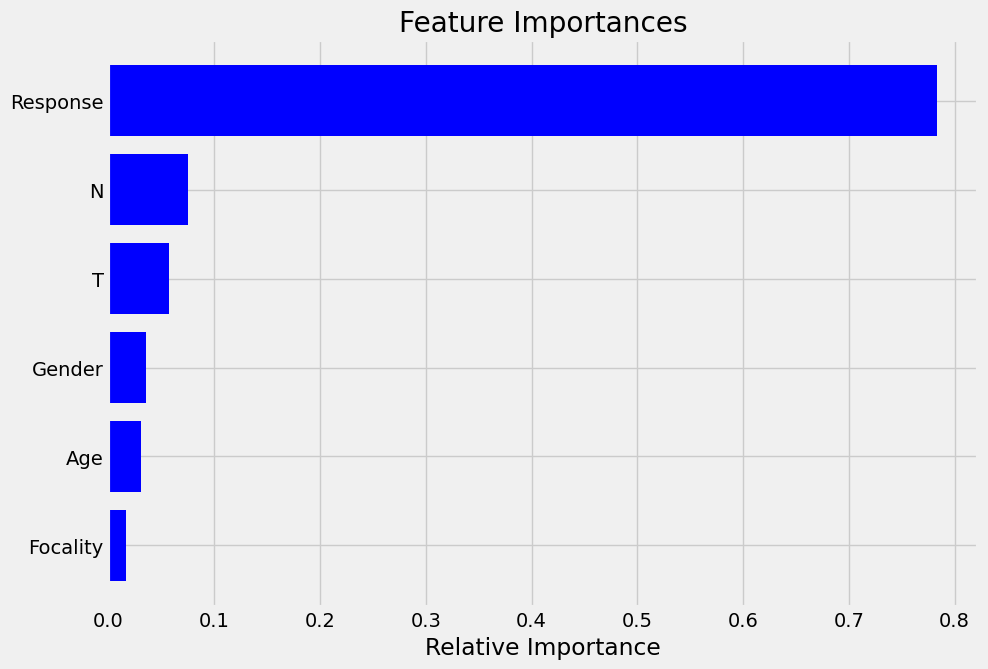

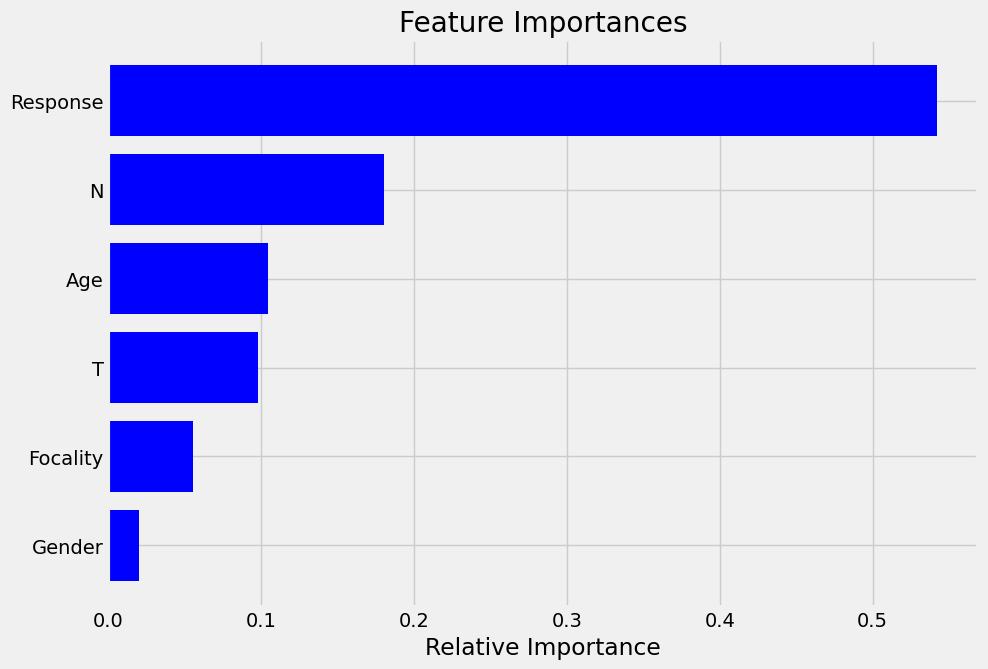

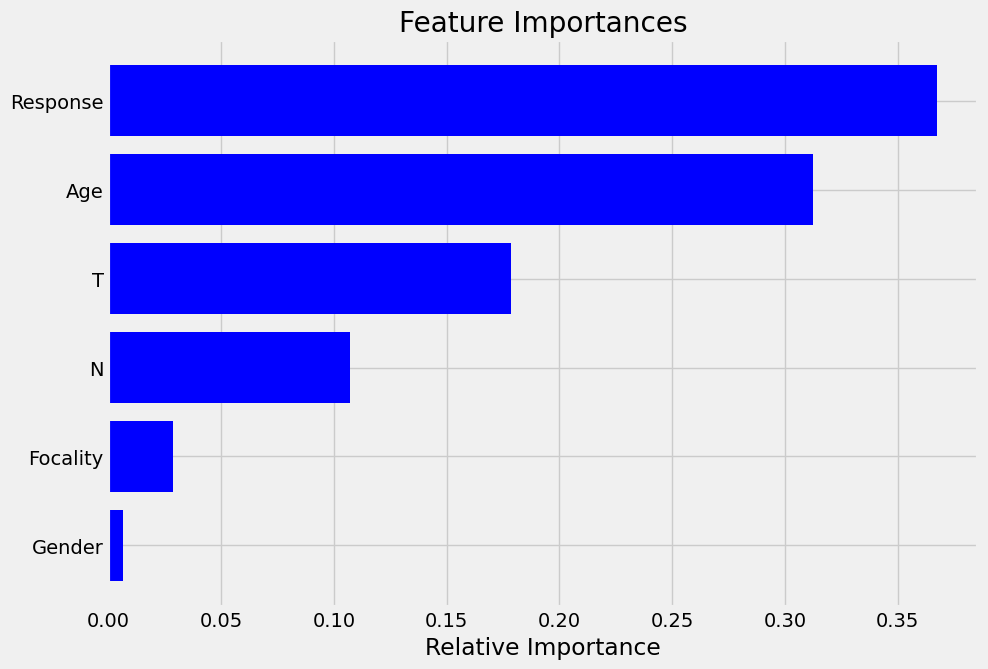

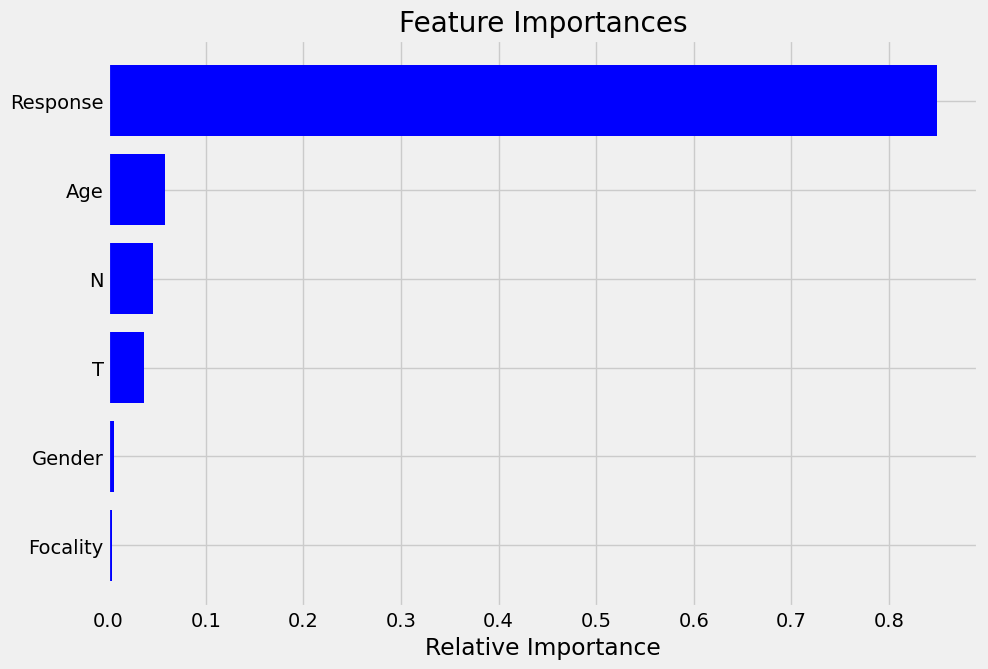

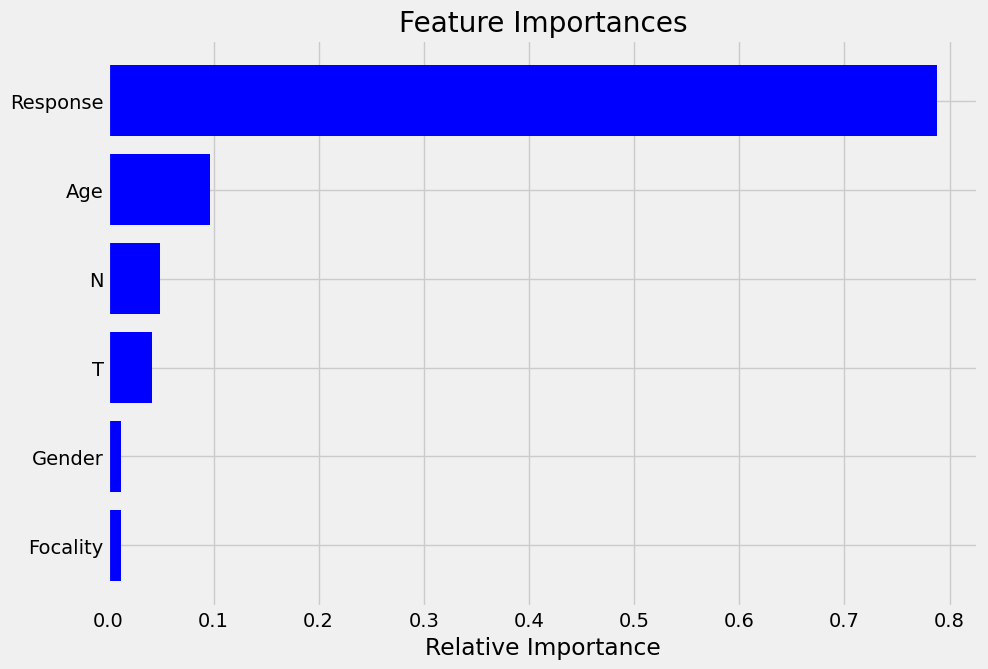

In [10]:
sm = sorted(model_scores, key=lambda x: x[5], reverse=True)

model_reports = []
for model in sm:
    # Calculate ROC Curve and AUC
    fpr, tpr, _ = roc_curve(model[1], model[3])
    model_roc_auc = auc(fpr, tpr) * 100
    model_accuracy = accuracy_score(model[1], model[2]) * 100
    cls_report = classification_report(model[1], model[2], output_dict=True)

    # Calculate Confusion Matrix
    cm = confusion_matrix(model[1], model[2])
    tn, fp, fn, tp = cm.ravel()

    # Calculate Sensitivity (Recall) and Specificity
    model_sensitivity = tp / (tp + fn) * 100 if (tp + fn) != 0 else 0
    model_specificity = tn / (tn + fp) * 100 if (tn + fp) != 0 else 0

    if USE_SHOW_MODEL_METRICS:
        print(f"Model = {model[0]}")
        print(f"Accuracy = {model_accuracy:.2f}")
        print(f"AUC = {model_roc_auc:.2f}")
        print(f"Sensitivity (Recall) = {model_sensitivity:.2f}")
        print(f"Specificity = {model_specificity:.2f}")

    if SHOW_CLASSIFICATION_REPORT:
        print(f"Classification Report : \n{cls_report}\n")

    if SHOW_ROC_CURVE:
        plt.figure(figsize=(10, 7))
        plt.plot(fpr, tpr, label=f"{model[0]} (AUC = {model_roc_auc:.2f})")
        plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve for Classification Models")
        plt.legend(loc="lower right")
        plt.show()

    if SHOW_CONFUSION_MATRIX:
        plt.figure(figsize=(10, 7))
        sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
        plt.title(f"Confusion Matrix for {model[0]}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

    if SHOW_FEATURE_IMPORTANCE:
        if hasattr(model[4], "feature_importances_"):
            feature_names = list(df.columns)
            importances = model[4].feature_importances_
            indices = np.argsort(importances)

            plt.figure(figsize=(10, 7))
            plt.title('Feature Importances')
            plt.barh(range(len(indices)), importances[indices], color='b', align='center')
            plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
            plt.xlabel('Relative Importance')
            plt.show()

    if USE_TEST_MODEL_PERFORMANCE:
        total_rows = len(df)
        matched_count = 0
        failed_predictions = []

        for index, row in df.iterrows():
            features = row.drop('Recurred').values.reshape(1, -1)
            actual = row['Recurred']
            predicted = model[4].predict(features)[0]

            if predicted == actual:
                matched_count += 1
            else:
                failed_predictions.append({'Row Number': index + 1, 'Actual': actual, 'Predicted': predicted})

        test_accuracy = (matched_count / total_rows) * 100

        model_reports.append({
            'Model Name': model[0],
            'Total Rows Processed': total_rows,
            'Successfully Matched': matched_count,
            'Failed Count': total_rows - matched_count,
            'Test Accuracy': f"{test_accuracy:.2f}",
            'Model Accuracy': f"{model_accuracy:.2f}",
            'Model Sensitivity': f"{model_sensitivity:.2f}",
            'Model Specificity': f"{model_specificity:.2f}",
            'Model AUC': f"{model_roc_auc:.2f}",
            'Failed Predictions': failed_predictions
        })

        if USE_SAVE_MODEL:
            joblib.dump(model[4], f'../model/pjas-thyroid-{model[0]}.pkl')
    
if USE_TEST_MODEL_PERFORMANCE:
    mr = sorted(model_reports, key=lambda x: x['Test Accuracy'], reverse=True)
    model_summary_report = pd.DataFrame(mr)
    model_summary_report.to_csv('../report/model_summary_report.csv', index=False)